In [1]:
from sklearn.preprocessing import LabelEncoder

def fillna(df):
    df["Age"].fillna(df["Age"].mean(), inplace = True)
    df["Cabin"].fillna("N", inplace = True)
    df["Embarked"].fillna("N", inplace = True)
    df["Fare"].fillna("0", inplace = True)
    return df

def drop_features(df):
    df.drop(["PassengerId", "Name", "Ticket"], axis = 1, inplace = True)
    return df

def format_features(df):
    df["Cabin"]= df["Cabin"].str[:1]
    features = ["Cabin", "Sex", "Embarked"]
    for feature in features:
        le = LabelEncoder()
        le = le.fit(df[feature])
        df[feature] = le.transform(df[feature])
    return df

def transform_features(df):
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("./train.csv")
y_df = df["Survived"]
X_df = df.drop("Survived", axis = 1)
X_df = transform_features(X_df)

X_train, X_test, y_train, y_test = train_test_split(X_df, y_df,
                                                    test_size = 0.2, random_state = 42)

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(solver = "liblinear")

lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_test, pred)
accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)

print(confusion)
print(accuracy)
print(precision)
print(recall)

[[90 15]
 [22 52]]
0.7932960893854749
0.7761194029850746
0.7027027027027027


In [5]:
pred_proba = lr_clf.predict_proba(X_test)

print("pred_groba() 결과 shpae:", pred_proba.shape)
print("pred_proba array 앞 3개의 샘플:", pred_proba[:3])

pred_proba_result = np.concatenate([pred_proba, pred.reshape(-1, 1)],
                                   axis = 1)
print("두개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측: ", pred_proba_result[:3])

pred_groba() 결과 shpae: (179, 2)
pred_proba array 앞 3개의 샘플: [[0.88326759 0.11673241]
 [0.79435838 0.20564162]
 [0.8518596  0.1481404 ]]
두개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측:  [[0.88326759 0.11673241 0.        ]
 [0.79435838 0.20564162 0.        ]
 [0.8518596  0.1481404  0.        ]]


In [6]:
from sklearn.preprocessing import Binarizer

X  = [[1, -1, 2],
      [2, 0, 0],
      [0, 1.1, 1.2]]
binarizer = Binarizer(threshold = 1.1)
print(binarizer.fit_transform(X))

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [7]:
custom_threshold = 0.6

pred_proba_1 = pred_proba[:, 1].reshape(-1, 1)
binarizer = Binarizer(threshold = custom_threshold).fit(pred_proba_1)
custom_pred = binarizer.transform(pred_proba_1)

confusion = confusion_matrix(y_test, custom_pred)
accuracy = accuracy_score(y_test, custom_pred)
precision = precision_score(y_test, custom_pred)
recall = recall_score(y_test, custom_pred)

print(confusion)
print(accuracy)
print(precision)
print(recall)

[[94 11]
 [24 50]]
0.8044692737430168
0.819672131147541
0.6756756756756757


In [8]:
from sklearn.metrics import precision_recall_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test,
                                                         pred_proba_class1)
print("반환된 분류 결정 임계값 배열의 모양: ", thresholds.shape)
print("반환된 분류 결정 정밀도 배열의 모양: ", precisions.shape)
print("반환된 분류 결정 재현율 배열의 모양: ", recall.shape)

print("thresholds 5 sample: ", thresholds[:5])
print("thresholds 5 sample: ", precisions[:5])
print("thresholds 5 sample: ", recalls[:5])

thr_index = np.arange(0, thresholds.shape[0], 15)
print("샘플 추출을 위한 임계갑값의 배열의 인덱스 10개:" , thr_index)
print("샘플 10개의 임계값:" , np.round(thresholds[thr_index], 2))

print("샘플 임계값별 정밀도: ", np.round(precisions[thr_index], 3))
print("샘플 임계값별 재현율: ", np.round(recalls[thr_index], 3))

반환된 분류 결정 임계값 배열의 모양:  (168,)
반환된 분류 결정 정밀도 배열의 모양:  (169,)
반환된 분류 결정 재현율 배열의 모양:  ()
thresholds 5 sample:  [0.09375626 0.09553834 0.09735065 0.09824914 0.09898309]
thresholds 5 sample:  [0.42774566 0.4244186  0.42690058 0.42941176 0.43195266]
thresholds 5 sample:  [1.         0.98648649 0.98648649 0.98648649 0.98648649]
샘플 추출을 위한 임계갑값의 배열의 인덱스 10개: [  0  15  30  45  60  75  90 105 120 135 150 165]
샘플 10개의 임계값: [0.09 0.12 0.14 0.15 0.2  0.29 0.36 0.57 0.66 0.73 0.87 0.93]
샘플 임계값별 정밀도:  [0.428 0.452 0.504 0.565 0.615 0.691 0.734 0.797 0.917 1.    1.    1.   ]
샘플 임계값별 재현율:  [1.    0.959 0.946 0.946 0.905 0.878 0.784 0.689 0.595 0.446 0.243 0.041]


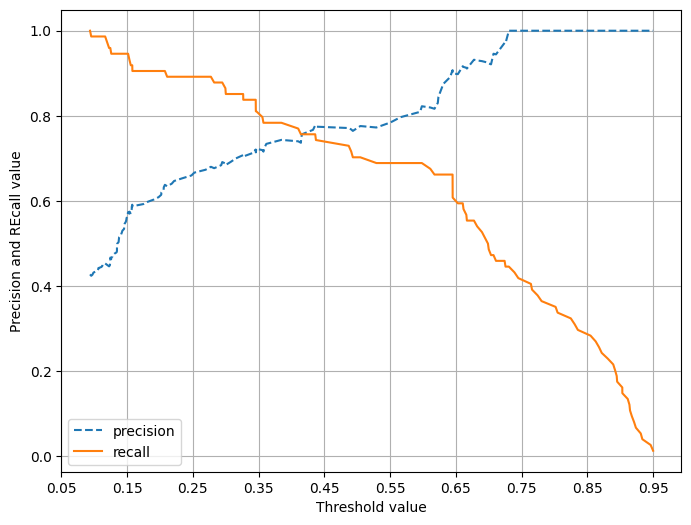

In [10]:
import matplotlib.pyplot as plt

def precision_recall_curve_plot(y_test, pred_proba_c1):
    precisions, recalls, thresholds = precision_recall_curve(y_test, pred_proba_c1)

    plt.figure(figsize = (8, 6))
    threshold_boundary = thresholds.shape[0]
    plt.plot(thresholds, precisions[0:threshold_boundary], linestyle = "--", label = "precision")
    plt.plot(thresholds, recalls[0:threshold_boundary], label = "recall")
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlabel("Threshold value")
    plt.ylabel("Precision and REcall value")
    plt.legend()
    plt.grid()
    plt.show()

precision_recall_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1])

In [11]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, pred)
print(f1)

0.7375886524822697


In [ ]:
from sklearn.metrics import roc_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:, 1]

# FPR = 1 - 특이도
# TPR = Recall
fprs, tprs, thresholds = roc_curve(y_test, pred_proba_class1)
thr_index = np.arange(1, thresholds.shape[0], 5)
print(np.round(fprs[thr_index], 3))
print(np.round(tprs[thr_index], 3))

[0.    0.019 0.048 0.143 0.19  0.248 0.295 0.486 0.695 0.838]
[0.014 0.473 0.595 0.689 0.784 0.838 0.892 0.919 0.946 0.986]


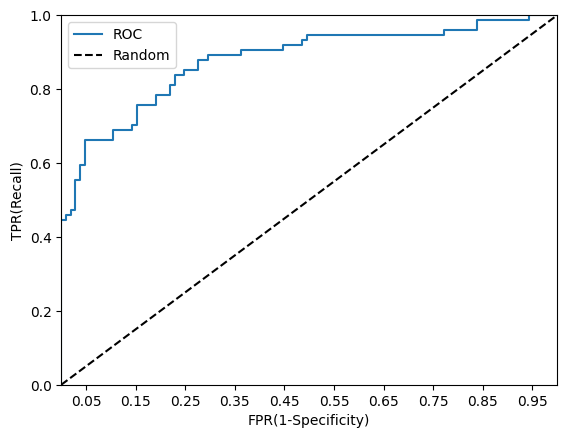

In [17]:
def roc_curve_plot(y_test, pred_proba_c1):
    fprs, tprs, thresholds = roc_curve(y_test, pred_proba_c1)
    plt.plot(fprs, tprs, label = "ROC")
    plt.plot([0, 1], [0, 1], "k--", label = "Random")
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("FPR(1-Specificity)")
    plt.ylabel("TPR(Recall)")
    plt.legend()
    plt.show()

roc_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1])

In [20]:
from sklearn.metrics import roc_auc_score
# pred_proba = lr_clf.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(y_test, lr_clf.predict_proba(X_test)[:, 1])
print(roc_score)

0.8774774774774776
